Shumo Wang 25/06/2026

This code uses several libraries to analyze the pressure and altitude data in file BMP581_NORMALMODEPressureReading.txt, which stores the pressure and converted absolute altitude reading from sensor in normal mode. Line charts and histograms are drawn to show the distribution of random errors.

In [2]:
# Import all essential modules
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

In [3]:
# open file
with open("BMP581_NORMALMODEPressureReading.txt", "r") as f:
    data = f.readlines()

# Declare both lists
Altitudes = []
Pressures = []

# Read file into two lists
data = data[2:]
for i in data:
    if not "Offset" in i and "Pressure (Pa)" in i:
        Pressures.append(float(i.strip()[15:]))
    elif "Altitude" in i:
        Altitudes.append(float(i.strip()[14:]))

# Store data in data frame
df = pd.DataFrame({"Time":[i*0.01 for i in range(len(Pressures))], "Pressure": Pressures, "Altitude": Altitudes})
df

,Time,Pressure,Altitude
0,0.00,101117.81,56.68
1,0.01,101117.98,56.67
2,0.02,101118.05,56.66
3,0.03,101118.50,56.63
4,0.04,101117.72,56.69
...,...,...,...
996,9.96,101117.88,56.68
997,9.97,101117.75,56.69
998,9.98,101118.70,56.61
999,9.99,101116.61,56.78


In [4]:
window = 50 # 50 datas in each window

# calculate rolling mean
df["rolling_mean"] = (
    df["Pressure"]
    .rolling(window=window, center=True)
    .mean() # calculate the mean of 50 datas
)

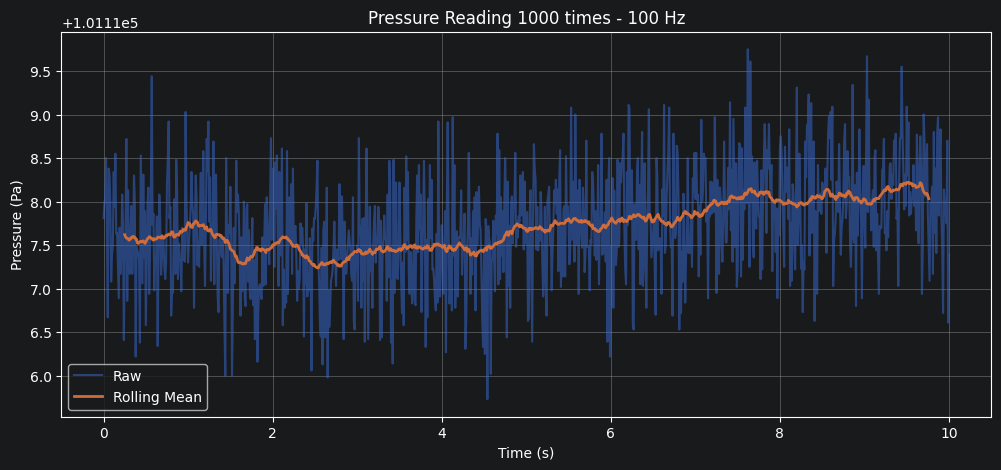

In [5]:
# plot the data into a line chart
plt.figure(figsize=(12,5))
plt.plot(df["Time"], df["Pressure"], alpha=0.5, label="Raw")
plt.plot(df["Time"], df["rolling_mean"], linewidth=2, label="Rolling Mean")
plt.xlabel("Time (s)")
plt.ylabel("Pressure (Pa)")
plt.title("Pressure Reading 1000 times - 100 Hz")
plt.grid(True)
plt.legend()
plt.show()

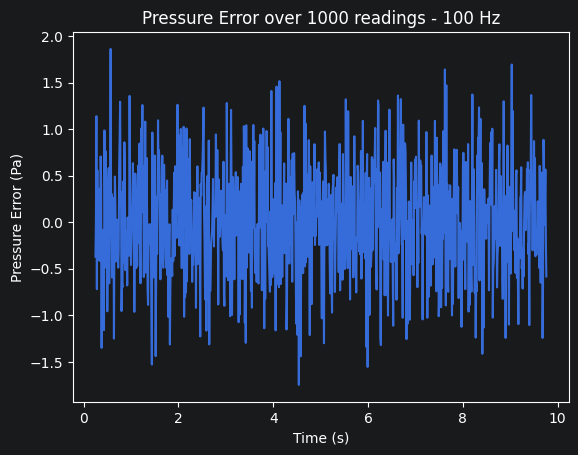

In [6]:
error = df["Pressure"] - df["rolling_mean"] # detrending data

# plot detrended data
plt.plot(df["Time"], error, label="Pressure")
plt.xlabel("Time (s)")
plt.ylabel("Pressure Error (Pa)")
plt.title("Pressure Error over 1000 readings - 100 Hz")
plt.show()

0.001222689075695919
0.5864441121603924


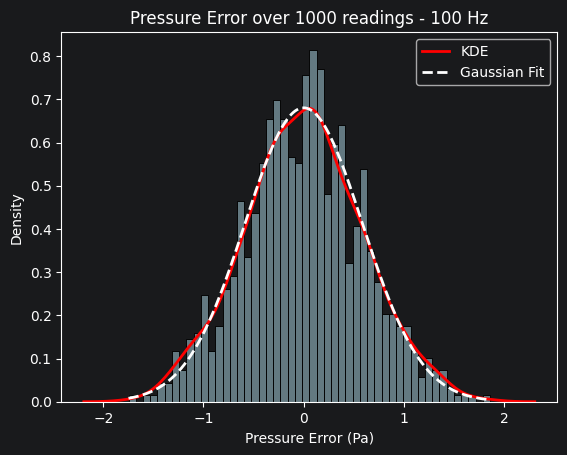

In [7]:
data = error.dropna() # drop any NaN term due to rolling mean

mu = data.mean() # calculate error mean
sigma = data.std() # calculate error standard deviation
print(mu)
print(sigma)

x = np.linspace(data.min(), data.max(), 1000)

# plot histogram
sns.histplot(data, bins=50, stat="density",
             color="lightblue", alpha=0.5)

# plot probability density function
sns.kdeplot(data,
            color="red",
            linewidth=2,
            label="KDE")

# plot Guassian distribution fit
plt.plot(x,
         norm.pdf(x, mu, sigma),
         color="white",
         linestyle="--",
         linewidth=2,
         label="Gaussian Fit")

plt.legend()
plt.title("Pressure Error over 1000 readings - 100 Hz")
plt.xlabel("Pressure Error (Pa)")
plt.show()

Same Operations repeated for altitude

In [8]:
window = 50 # 50 datas

df["rolling_mean_altitude"] = (
    df["Altitude"]
    .rolling(window=window, center=True)
    .mean() # calculate the mean of 50 datas
)

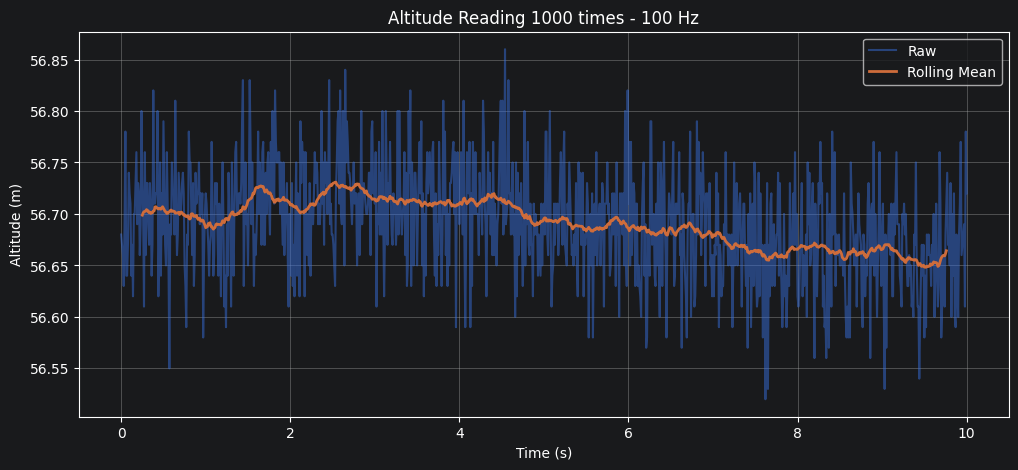

In [9]:
plt.figure(figsize=(12,5))
plt.plot(df["Time"], df["Altitude"], alpha=0.5, label="Raw")
plt.plot(df["Time"], df["rolling_mean_altitude"], linewidth=2, label="Rolling Mean")
plt.xlabel("Time (s)")
plt.ylabel("Altitude (m)")
plt.title("Altitude Reading 1000 times - 100 Hz")
plt.grid(True)
plt.legend()
plt.show()
error_altitude = df["Altitude"] - df["rolling_mean_altitude"]

-0.00010903361344543004
0.048948178807069406


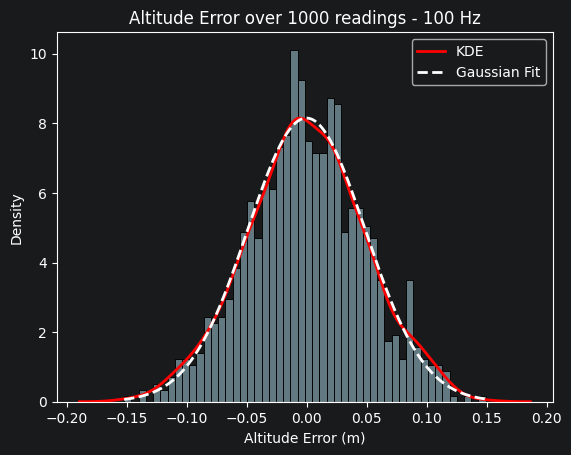

In [10]:
data = error_altitude.dropna()

mu = data.mean()
sigma = data.std()
print(mu)
print(sigma)

x = np.linspace(data.min(), data.max(), 1000)

sns.histplot(data, bins=50, stat="density",
             color="lightblue", alpha=0.5)

sns.kdeplot(data,
            color="red",
            linewidth=2,
            label="KDE")

plt.plot(x,
         norm.pdf(x, mu, sigma),
         color="white",
         linestyle="--",
         linewidth=2,
         label="Gaussian Fit")

plt.legend()
plt.title("Altitude Error over 1000 readings - 100 Hz")
plt.xlabel("Altitude Error (m)")
plt.show()